# Method 1: minutes-based shrinkage, per position group

**Question.** A forward with 120 minutes and 2 goals has a goals/90 of 1.5. Is that real?

**Idea in plain words.** A player's per-90 number is *real ability* plus *luck*. Luck matters a lot
when minutes are low and very little when minutes are high. So we blend the player's number with the
group average, trusting the player's own number more as minutes grow:

`estimate = w * raw + (1 - w) * group_average`, with `w = minutes / (minutes + k)`

`k` is the number of minutes where we trust the player and the average equally. Noisy stats (goals)
need a bigger `k` than steady ones (passes).

**Why per position group.** A centre back's "average" interceptions/90 is not a winger's. Each tactical group
(GK, Outside Backs, Center Backs, Wingers, Center Forwards, Attacking Midfielders, Central Midfielders) gets its own
average, its own `k` and its own stats. A player's season is assigned to a group by the position code of each match
they played, and only the minutes played in that role count. A player who split a season between two roles shows up
once in each.

**Plan.** *Part A* walks through one group step by step. *Part B* repeats the experiment for every group and compares.

In [1]:
import sys
sys.path.append("..")  # so we can import the analysis/ folder from the repo root

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from analysis import common
from analysis import minutes_shrinkage as ms
sns.set_theme(style="whitegrid", context="notebook")

GENDER = "female"
DEEP_DIVE = "Center Forwards"   # the group we walk through step by step in part A
STAT = common.STAT_COLS[DEEP_DIVE][0]  # the stat we zoom in on in the plots (goals)

con = common.connect()
# One entry per tactical group: player-seasons, per-90 rates, season t -> t+1 pairs.
data = {group: common.prepare_group(con, GENDER, group) for group in common.GROUPS}

overview = pd.DataFrame({
    group: {"player-seasons": len(d.terms),
            "players": d.terms["player_id"].nunique(),
            "with next season": len(d.pairs),
            "median minutes": d.terms["minutes"].median(),
            "share under 250 min": (d.terms["minutes"] < 250).mean()}
    for group, d in data.items()}).T
overview.round(2)

,player-seasons,players,with next season,median minutes,share under 250 min
GK,4958.0,2588.0,1387.0,463.5,0.41
Outside Backs,18798.0,11331.0,2548.0,145.0,0.60
Center Backs,13158.0,7777.0,2811.0,287.0,0.48
Wingers,18827.0,11540.0,482.0,80.0,0.81
Center Forwards,18936.0,11196.0,1534.0,103.0,0.69
Attacking Midfielders,23820.0,13712.0,995.0,100.0,0.74
Central Midfielders,23003.0,13377.0,3098.0,139.0,0.61


# Part A: one group in detail

Deep dive: Center Forwards, stat = goals


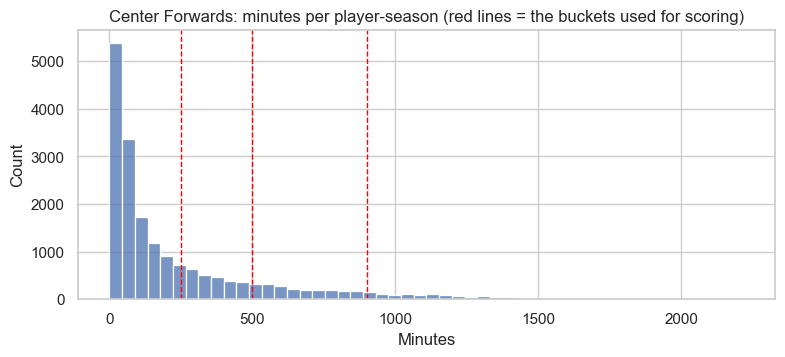

In [2]:
d = data[DEEP_DIVE]
print(f"Deep dive: {DEEP_DIVE}, stat = {STAT}")
fig, ax = plt.subplots(figsize=(9, 3.5))
sns.histplot(d.terms["minutes"], bins=50, ax=ax)
for edge in common.BUCKET_EDGES[1:-1]:
    ax.axvline(edge, color="red", linestyle="--", linewidth=1)
ax.set_title(f"{DEEP_DIVE}: minutes per player-season (red lines = the buckets used for scoring)")
ax.set_xlabel("Minutes")
plt.show()

## A1. See the noise

If low-minute numbers were noisy copies of the same truth, we'd expect a **funnel**: wide scatter on the
left (few minutes), narrowing to the right. The red line is the group average.

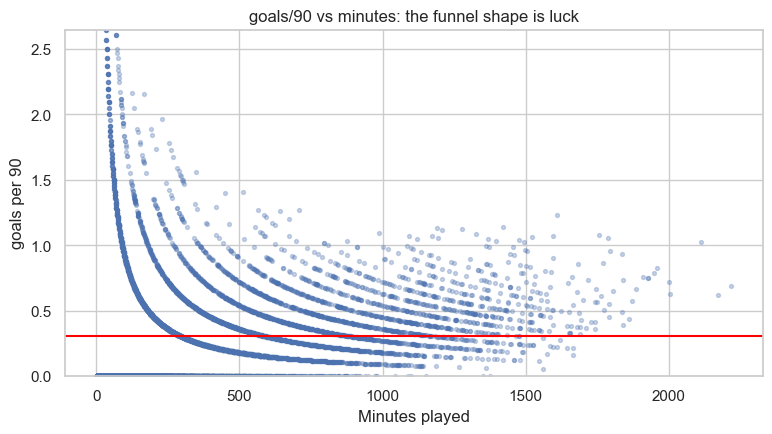

In [3]:
means = pd.Series({s: ms.group_mean(d.all_rates[s], d.terms["minutes"]) for s in d.all_rates})

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.scatter(d.terms["minutes"], d.all_rates[STAT], s=8, alpha=0.3)
ax.axhline(means[STAT], color="red")
ax.set_ylim(0, d.all_rates[STAT].quantile(0.995))
ax.set_xlabel("Minutes played"); ax.set_ylabel(f"{STAT} per 90")
ax.set_title(f"{STAT}/90 vs minutes: the funnel shape is luck")
plt.show()

## A2. Estimate `k` for every stat

`estimate_k` assumes each player's rate = group mean + real differences + luck that shrinks with
minutes, then finds the amounts of "real differences" and "luck" that fit the data best.
A large `k` means a stat is mostly luck for a long time.

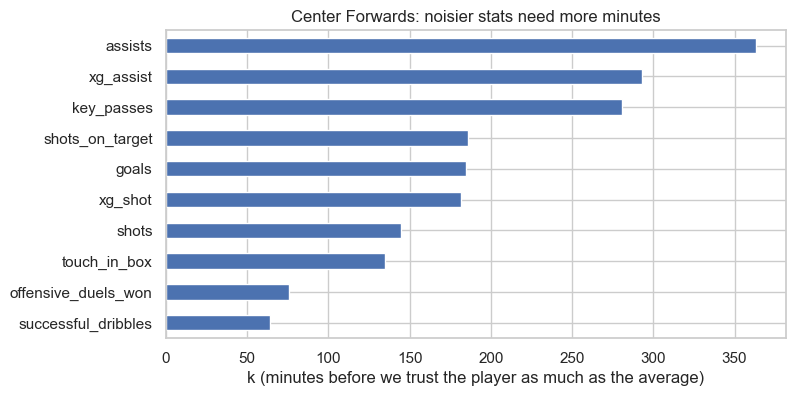

In [4]:
k = ms.estimate_all_k(d.all_rates, d.terms["minutes"])

fig, ax = plt.subplots(figsize=(8, 4))
k.sort_values().plot.barh(ax=ax)
ax.set_xlabel("k (minutes before we trust the player as much as the average)")
ax.set_title(f"{DEEP_DIVE}: noisier stats need more minutes")
plt.show()

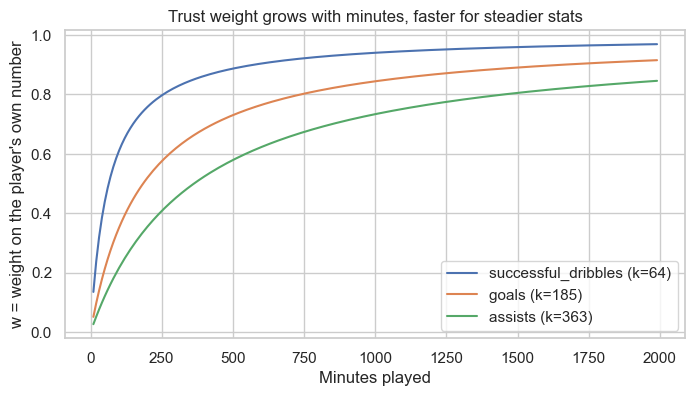

In [5]:
# How much weight does the player's own number get?
minutes_grid = pd.Series(np.arange(10, 2000, 10))
fig, ax = plt.subplots(figsize=(8, 4))
for stat in [k.idxmin(), STAT, k.idxmax()]:
    ax.plot(minutes_grid, ms.trust_weight(minutes_grid, k[stat]), label=f"{stat} (k={k[stat]:.0f})")
ax.set_xlabel("Minutes played"); ax.set_ylabel("w = weight on the player's own number")
ax.set_title("Trust weight grows with minutes, faster for steadier stats")
ax.legend()
plt.show()

## A3. Apply the shrinkage and check it did what we expect

Share of players moved toward the mean: 100%


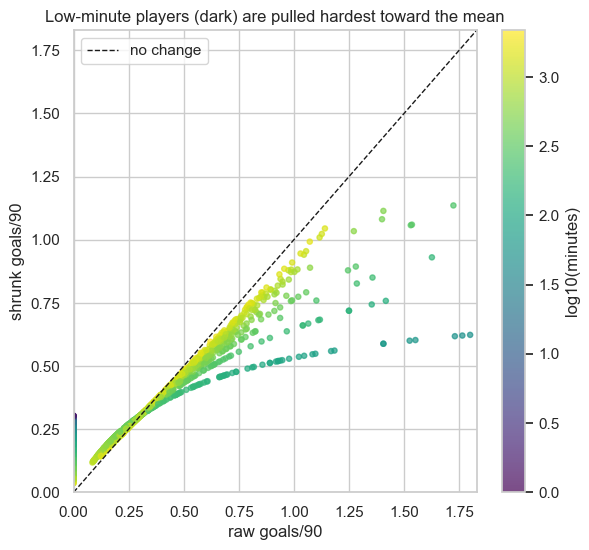

In [6]:
shrunk = ms.shrink(d.raw, d.minutes, k, means)

# Sanity check: every shrunk value should sit between the raw value and the group mean.
moved_toward_mean = ((shrunk[STAT] - means[STAT]).abs() <= (d.raw[STAT] - means[STAT]).abs() + 1e-9).mean()
print(f"Share of players moved toward the mean: {moved_toward_mean:.0%}")

fig, ax = plt.subplots(figsize=(6.5, 6))
points = ax.scatter(d.raw[STAT], shrunk[STAT], c=np.log10(d.minutes), cmap="viridis", s=14, alpha=0.7)
limit = d.raw[STAT].quantile(0.995)
ax.plot([0, limit], [0, limit], "k--", linewidth=1, label="no change")
ax.set_xlim(0, limit); ax.set_ylim(0, limit)
ax.set_xlabel(f"raw {STAT}/90"); ax.set_ylabel(f"shrunk {STAT}/90")
plt.colorbar(points, label="log10(minutes)")
ax.legend(); ax.set_title("Low-minute players (dark) are pulled hardest toward the mean")
plt.show()

Players whose number changed the most (high raw rates built on very few minutes):

In [7]:
change = (d.raw[STAT] - shrunk[STAT]).abs().sort_values(ascending=False).head(10).index
pd.DataFrame({"player_id": d.pairs.loc[change, "player_id"], "minutes": d.minutes[change],
              f"raw {STAT}/90": d.raw.loc[change, STAT].round(2),
              f"shrunk {STAT}/90": shrunk.loc[change, STAT].round(2),
              f"next season {STAT}/90": d.target.loc[change, STAT].round(2)})

,player_id,minutes,raw goals/90,shrunk goals/90,next season goals/90
266,841545,15.0,6.00,0.73,0.71
1102,759103,44.0,4.09,1.03,0.30
83,950416,45.0,4.00,1.03,0.31
1297,759038,74.0,2.43,0.91,0.51
1532,765871,50.0,1.80,0.62,0.40
376,922763,51.0,1.76,0.62,0.24
86,668683,90.0,2.00,0.86,0.37
431,705185,52.0,1.73,0.62,0.00
1349,841644,93.0,1.94,0.85,0.44
743,711752,94.0,1.91,0.85,0.24


# Part B: every position group

Same steps for all groups. We score each estimate against the same player's per-90 rate the *following* year
(only players with 600+ minutes next year, so the target is not mostly luck). Lower RMSE and higher Spearman are better.

In [8]:
# Fit k and the group means on every player-season of the group, then shrink the paired players.
fits = {}
for group, d in data.items():
    k = ms.estimate_all_k(d.all_rates, d.terms["minutes"])
    means = pd.Series({s: ms.group_mean(d.all_rates[s], d.terms["minutes"]) for s in d.all_rates})
    fits[group] = {"k": k, "means": means, "shrunk": ms.shrink(d.raw, d.minutes, k, means)}

## B1. How noisy is each stat, in each group?

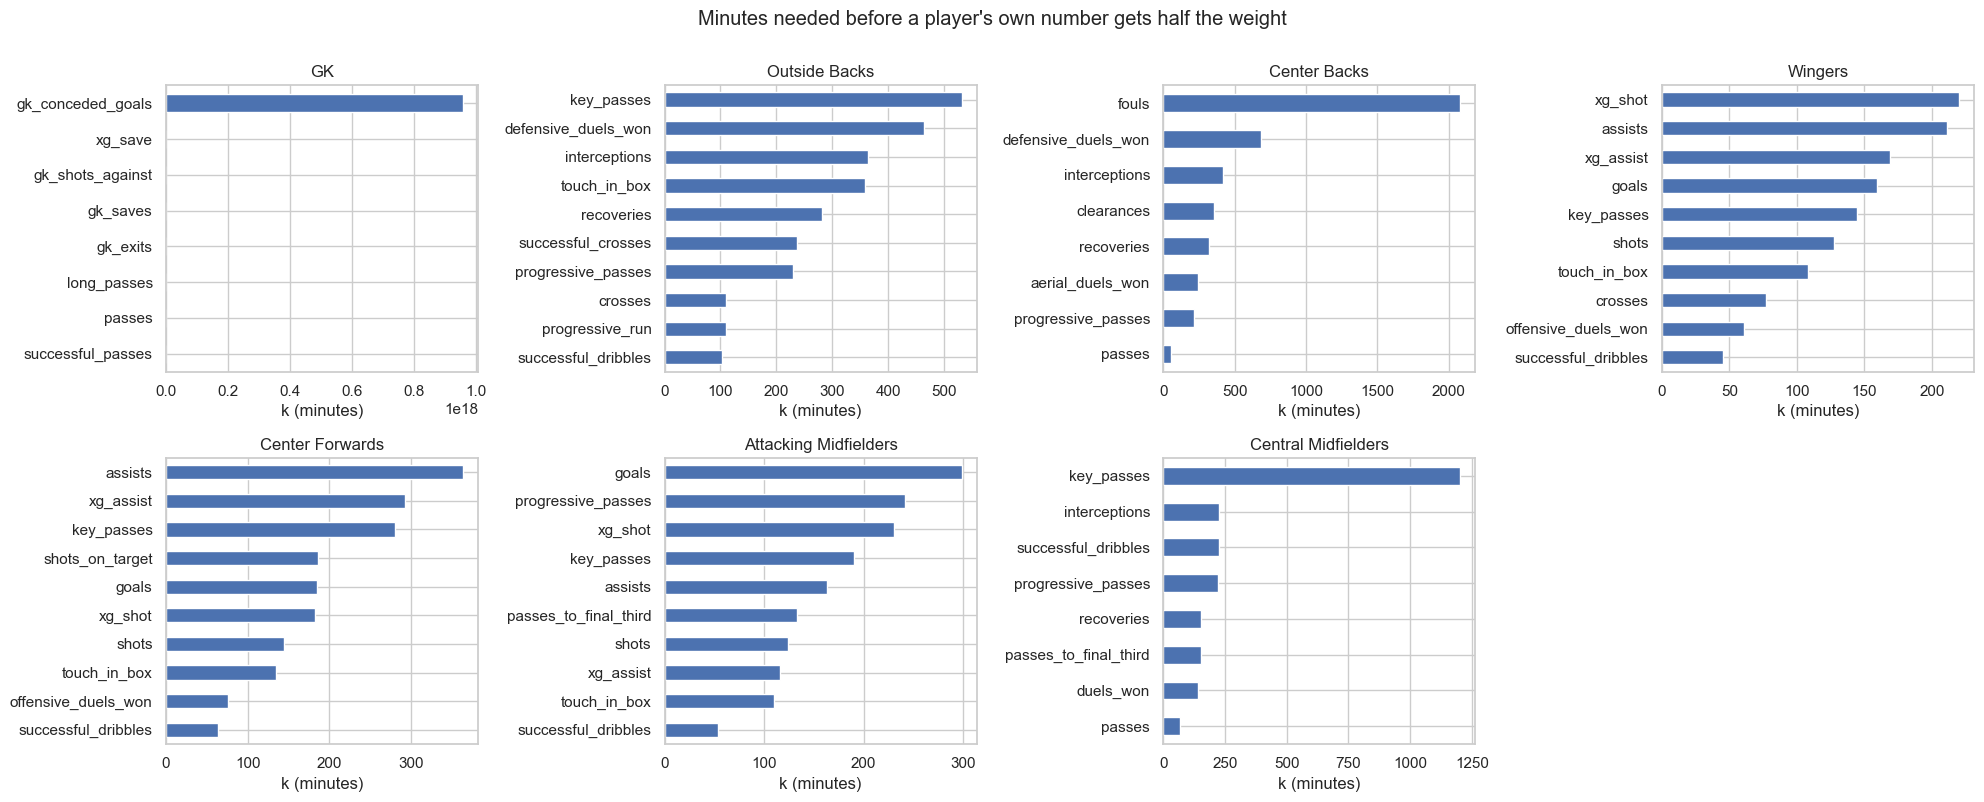

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, group in zip(axes.flat, common.GROUPS):
    fits[group]["k"].sort_values().plot.barh(ax=ax)
    ax.set_title(group); ax.set_xlabel("k (minutes)")
for ax in axes.flat[len(common.GROUPS):]:
    ax.axis("off")
plt.suptitle("Minutes needed before a player's own number gets half the weight", y=1.0)
plt.tight_layout(); plt.show()

## B2. Does shrinkage predict next season better than the raw number?

In [10]:
BUCKET_COLUMNS = ["all"] + common.BUCKET_LABELS


def score_matrix(results: dict, method: str, metric: str) -> pd.DataFrame:
    """Rows = position groups, columns = minute buckets: how much `method` beats raw.

    For RMSE the number is the percent drop in error; for Spearman it is the change in
    correlation. In both cases positive means better than raw.
    """
    rows = {}
    for group, scores in results.items():
        before, after = scores["raw"][metric], scores[method][metric]
        rows[group] = (before - after) / before * 100 if metric == "rmse" else after - before
    return pd.DataFrame(rows).T.reindex(columns=BUCKET_COLUMNS)


def plot_gain(results: dict, methods: list):
    """One heatmap pair (RMSE gain, Spearman gain) per method."""
    fig, axes = plt.subplots(len(methods), 2, figsize=(14, 4.2 * len(methods)), squeeze=False)
    for row, method in zip(axes, methods):
        for ax, metric, fmt, title in zip(row, ["rmse", "spearman"], [".0f", ".2f"],
                                          ["% drop in RMSE vs raw", "change in Spearman vs raw"]):
            matrix = score_matrix(results, method, metric)
            limit = np.nanmax(np.abs(matrix.to_numpy()))
            sns.heatmap(matrix, annot=True, fmt=fmt, cmap="RdYlGn", center=0, vmin=-limit, vmax=limit,
                        cbar=False, ax=ax)
            ax.set_title(f"{method}: {title} (green = better)")
            ax.set_xlabel("Minutes played in season t"); ax.set_ylabel("")
    plt.tight_layout()
    plt.show()

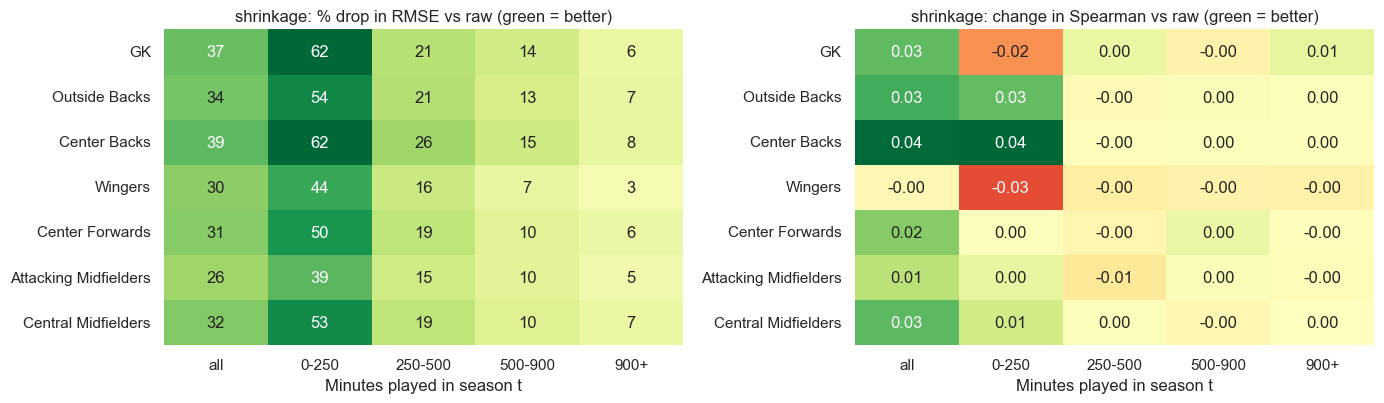

In [11]:
results = {}
for group, d in data.items():
    results[group] = {"raw": common.evaluate(d.raw, d.target, d.minutes),
                      "shrinkage": common.evaluate(fits[group]["shrunk"], d.target, d.minutes)}
plot_gain(results, ["shrinkage"])

In [12]:
# The same numbers as a table.
pd.concat({g: pd.concat(r, names=["method"]) for g, r in results.items()}, names=["group"]).round(3)

n  spearman   rmse
group               method    bucket                        
GK                  raw       all      1387     0.451  1.427
                              0-250     253     0.331  2.533
                              250-500   132     0.401  1.330
                              500-900   195     0.415  1.153
                              900+      807     0.538  0.893
...                                     ...       ...    ...
Central Midfielders shrinkage all      3098     0.535  0.851
                              0-250     633     0.302  0.969
                              250-500   544     0.493  0.889
                              500-900   743     0.564  0.834
                              900+     1178     0.628  0.769

[70 rows x 3 columns]

## B3. Is the estimated `k` the best `k`?

The `k` above only accounts for luck *within* a season. Players also change from year to year, so the best `k` for
predicting *next* year may be larger. We scale `k` by a multiplier and track the RMSE relative to raw.
(This peeks at next season, so treat it as a diagnostic, not a tuned method.)

C:\Users\zcoch\DSC-180-Sports-Soccer-Capstone\notebooks\..\analysis\common.py:202: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho = [spearmanr(est[c], tgt[c])[0] for c in est.columns]


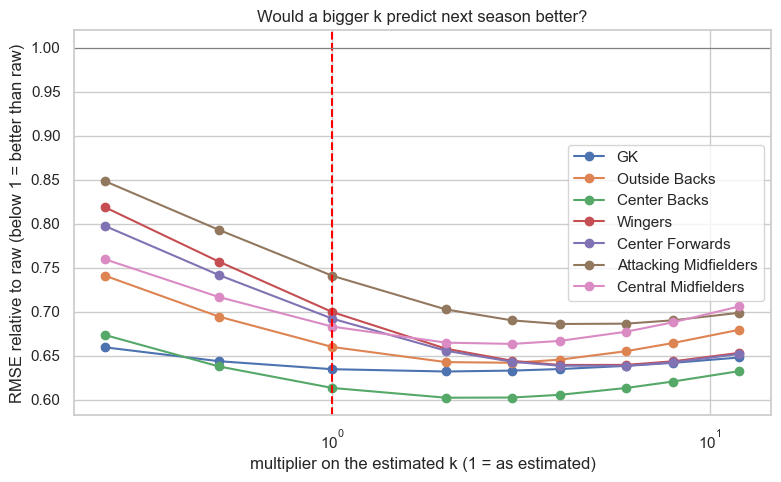

In [13]:
multipliers = [0.25, 0.5, 1, 2, 3, 4, 6, 8, 12]
scan = {}
for group, d in data.items():
    base = common.evaluate(d.raw, d.target, d.minutes).loc["all", "rmse"]
    scan[group] = [common.evaluate(ms.shrink(d.raw, d.minutes, fits[group]["k"] * m, fits[group]["means"]),
                                   d.target, d.minutes).loc["all", "rmse"] / base for m in multipliers]
scan = pd.DataFrame(scan, index=multipliers)

fig, ax = plt.subplots(figsize=(9, 5))
scan.plot(marker="o", ax=ax, logx=True)
ax.axvline(1, color="red", linestyle="--"); ax.axhline(1, color="grey", linewidth=0.8)
ax.set_xlabel("multiplier on the estimated k (1 = as estimated)")
ax.set_ylabel("RMSE relative to raw (below 1 = better than raw)")
ax.set_title("Would a bigger k predict next season better?")
plt.show()

## Takeaways

Female players, scored against next season. "Drop in RMSE" is relative to using the raw per-90.

* **Error drops in every group.** Overall RMSE falls 26-39%. For players under 250 minutes it falls 39-62%, and it still falls 3-8% for players with 900+ minutes, because even a full season of a noisy stat contains luck.
* **Center Backs, GK and Outside Backs gain the most; Attacking Midfielders and Wingers the least.** Their stats are mostly steady counting numbers (clearances, interceptions, saves). Attacking players are judged on rare events like goals, so more of what remains is still luck. Wingers and Attacking Midfielders also have the fewest players with a next season (482 and 995 pairs), so their scores are less reliable.
* **Rank order barely changes** (Spearman moves by at most about 0.04, in either direction). Shrinkage fixes the *size* of the numbers, not who is ahead of whom among players with similar minutes.
* **The estimated `k` is on the cautious side.** In section B3 a `k` 2-4 times larger predicts next season a bit better for most groups, while Center Backs and GK are almost flat. This peeks at next season, so it is a diagnostic and not a tuned method.
* **Limit:** shrinkage uses only one stat at a time and pulls everyone toward one group average, so it cannot tell a low-minute star from a low-minute scrub.